In [1]:
# ====================================
# Import libraries
# ====================================
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import random_split, DataLoader
import torchvision.transforms.v2 as T
from torch.utils.data import TensorDataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random

In [2]:
#Check whether a GPU is available
print("GPU available:", torch.cuda.is_available())

#Check which GPU is being used
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

GPU available: True
GPU name: Tesla T4


In [3]:
# ====================================
# Reproducibility and device
# ====================================
r_seed = 99
generator = torch.Generator()

def reset_seed(seed=r_seed):
    """Reset all seeds at once."""
    random.seed(seed) #reset python random seed
    np.random.seed(seed) #reset numpy random seed
    torch.manual_seed(seed) #reset pytorch random seed
    generator.manual_seed(seed) #reset the dataloader random seed
    if torch.cuda.is_available(): #if we use the gpu
        torch.cuda.manual_seed_all(seed)

reset_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:
#This cell runs on Google Colab if you save the data files in a folder called "data" in Drive.
#To run locally, skip this cell and set the paths to data/075_images.npy

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# ====================================
# Load the Clock dataset (75x75)
# ====================================
images_path = '/content/drive/MyDrive/DL_Assignment_1/data/075_images.npy'
labels_path = '/content/drive/MyDrive/DL_Assignment_1/data/075_labels.npy'

images_np = np.load(images_path)
labels_np = np.load(labels_path)

#Check out our images
    #No longer needed at this point

#Convert into pytorch tensors
images = torch.from_numpy(images_np).float() #turn numpy array into pytorch tensor, float
images = images.unsqueeze(1) #add channel dimension, we need format (batch_size, channels, height, width) (greyscale = 1 channel)
mean = images.mean()
std = images.std()
images = (images - mean) / std #standardize the pixels (easier for training)

labels_minutes = torch.from_numpy(labels_np[:, 0] * 60 + labels_np[:, 1]).long() #hours*60 + minutes, and turn it into pytorch tensor
print(labels_minutes.shape, labels_minutes.min(), labels_minutes.max()) #18'000 labels, 1 dimension (min). Minutes go from 0 (00:00) to 719 (11:59).

#We are trying to predict:
#Hours: from 0 to 11.
#Minutes: from 0 to 59.
#Total minutes: sum of hours (in minutes) + minutes (12 hours*60 = 720 minutes).

torch.Size([18000]) tensor(0) tensor(719)


In [6]:
#=====================================
# Train-Validation-Test split
# ====================================
reset_seed()

dataset = TensorDataset(images, labels_minutes)
n = len(dataset)

train_size = int(0.8 * n)
valid_size = int(0.1 * n)
test_size = n - train_size - valid_size

train_data, valid_data, test_data = random_split(
    dataset,
    [train_size, valid_size, test_size],
    generator=generator
)

batch_size = 64

train_dataloader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True,
    generator=generator
)

valid_dataloader = DataLoader(
    valid_data,
    batch_size=batch_size,
    shuffle=True
)

test_dataloader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=True
)

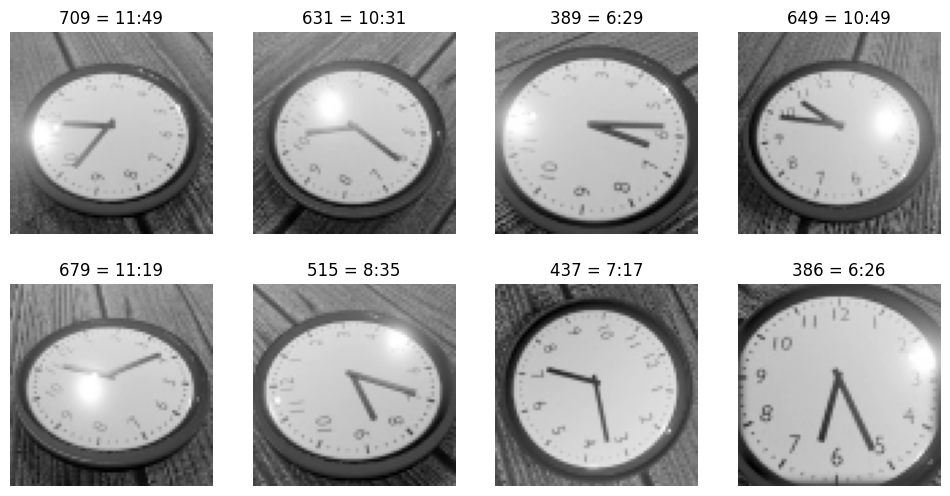

In [7]:
#=====================================
# Trying to see images
# ====================================
images_batch, labels_batch = next(iter(train_dataloader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, img, y in zip(axes.flat, images_batch, labels_batch):
    m = y.item() #number of minutes from midnight
    ax.imshow(img[0]*std + mean, cmap="gray")
    ax.set_title(f"{m} = {m // 60}:{m % 60:02d}")
    ax.axis("off")
plt.show()

In [8]:
# =====================================
# Setting up the CNN
# =====================================

class Net_4conv(nn.Module):   #Final CNN
    def __init__(self, num_classes):  #allow to provide a desired number of classes
        super().__init__()
        #Input image (1, 75, 75) (greyscale, 75x75)
        self.conv1 = nn.Conv2d(1, 6, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv4 = nn.Conv2d(32, 64, 3, padding=1)
        self.fc1 = nn.Linear(64 * 4 * 4, 120)
        self.fc2 = nn.Linear(120, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [9]:
# ======================================================
# Defining the functions for training and evaluation
# ======================================================


#Train the model

def train_model(model, train_dataloader, optimizer, criterion, epochs, bin_size):

    """Train a model for a given number of epochs."""

    for epoch in range(epochs):

        model.train()
        running_loss = 0.0

        for inputs, minutes in train_dataloader:

            #data agumentation
            #inputs = train_transform(inputs)

            #To use external GPU
            inputs = inputs.to(device)
            minutes = minutes.to(device)

            #convert the labels from labels in minutes (e.g., 01:30 --> 90 minutes) to labels in classes (e.g., class 3)
            labels_class = (minutes // bin_size).long()

            #zero the parameter gradients
            optimizer.zero_grad()

            #forward + backward + optimize
            outputs = model(inputs) #predictions
            loss = criterion(outputs, labels_class) #compute loss
            loss.backward() #compute gradients
            optimizer.step() #optimize weights

            #compute running loss
            running_loss += loss.item()
        print(
            f"Epoch {epoch + 1}/{epochs}: "
            f"- Loss = {running_loss/len(train_dataloader):.4f}"
        )

#Validate the model

def evaluate_model(model, dataloader, bin_size):

    """Evaluate a model using the average circular time error."""

    model.eval()

    total_error = 0
    total = 0

    with torch.no_grad():
        for inputs, minutes in dataloader:

            #To use external GPU
            inputs = inputs.to(device)
            minutes = minutes.to(device)

            #Get predictions and classes
            outputs = model(inputs) #predictions (in classes!!!)
            predictions = outputs.argmax(dim=1) #assign to the class with the highest score

            #Convert predicted classes back into total minutes
            predicted_minutes = predictions * bin_size + (bin_size - 1) / 2 #midpoint to represent the class

            #Calculate absolute difference and the circular difference
            difference = torch.abs(predicted_minutes - minutes)
            circular_difference = torch.minimum(difference, 720 - difference)

            #Compute the errors
            total_error += circular_difference.sum().item()
            total += minutes.size(0)

    common_sense_error = total_error / total

    return common_sense_error

In [10]:
# =====================================
# Experiment with different bin sizes
# =====================================

bin_sizes = [30, 15, 5, 1] #30 minutes bins, 15 minutes bins, 5 minutes bins, 1 minute bins
epochs = 20
learning_rate = 0.001
results, models = [], {}

for bin_size in bin_sizes:

    #Calculate number of classes
    num_classes = 720 // bin_size

    print(f"\nExperiment: {bin_size}-minute bins ({num_classes} classes), {epochs} epochs")

    #New seed for every experiment
    reset_seed()

    #Create a new CNN
    model = Net_4conv(num_classes).to(device)

    #Loss function
    criterion = nn.CrossEntropyLoss()

    #Optimizer
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    #Train model
    train_model(
        model,
        train_dataloader,
        optimizer,
        criterion,
        epochs,
        bin_size
    )

    #Evaluate model
    valid_error = evaluate_model(
        model,
        valid_dataloader,
        bin_size
    )

    models[bin_size] = model

    # Store results
    results.append({
        "Bin size": bin_size,
        "Number of classes": num_classes,
        "Validation common-sense error (min)": valid_error
    })

    pd.DataFrame(results).to_csv("results_class.csv", index=False)
    print(f"\nCommon-sense error: {valid_error:.2f} minutes")

results_df = pd.DataFrame(results)
print(results_df)


Experiment: 30-minute bins (24 classes), 20 epochs
Epoch 1/20: - Loss = 3.1793
Epoch 2/20: - Loss = 3.1779
Epoch 3/20: - Loss = 2.8017
Epoch 4/20: - Loss = 2.1326
Epoch 5/20: - Loss = 1.6709
Epoch 6/20: - Loss = 1.3338
Epoch 7/20: - Loss = 1.1172
Epoch 8/20: - Loss = 0.9551
Epoch 9/20: - Loss = 0.8308
Epoch 10/20: - Loss = 0.7459
Epoch 11/20: - Loss = 0.6559
Epoch 12/20: - Loss = 0.5994
Epoch 13/20: - Loss = 0.5448
Epoch 14/20: - Loss = 0.5029
Epoch 15/20: - Loss = 0.4675
Epoch 16/20: - Loss = 0.4212
Epoch 17/20: - Loss = 0.4110
Epoch 18/20: - Loss = 0.3765
Epoch 19/20: - Loss = 0.3561
Epoch 20/20: - Loss = 0.3168

Common-sense error: 21.91 minutes

Experiment: 15-minute bins (48 classes), 20 epochs
Epoch 1/20: - Loss = 3.8731
Epoch 2/20: - Loss = 3.8722
Epoch 3/20: - Loss = 3.8719
Epoch 4/20: - Loss = 3.8718
Epoch 5/20: - Loss = 3.8539
Epoch 6/20: - Loss = 3.6093
Epoch 7/20: - Loss = 3.1684
Epoch 8/20: - Loss = 2.5337
Epoch 9/20: - Loss = 1.9117
Epoch 10/20: - Loss = 1.5574
Epoch 11/

In [11]:
# =====================================
# Extra Experiment for the smallest bin size
# =====================================

#The question is: would it improve if we gave it more training time?
bin_size_small = 1 #1 minute bins
epochs_small = 100
learning_rate = 0.001
num_classes_small = 720 // bin_size_small

print(f"\nExtra experiment: {bin_size_small}-minute bins ({num_classes_small} classes), {epochs_small} epochs")

#New seed for every experiment
reset_seed()

#Create a new CNN
model_small = Net_4conv(num_classes_small).to(device)

#Loss function
criterion = nn.CrossEntropyLoss()

#Optimizer
optimizer = optim.Adam(model_small.parameters(), lr=learning_rate)

#Train model
train_model(
    model_small,
    train_dataloader,
    optimizer,
    criterion,
    epochs_small,
    bin_size_small
)

#Evaluate model
valid_error_small = evaluate_model(model_small, valid_dataloader, bin_size_small)

#Store results
results_small_df = pd.DataFrame([{
    "Bin size": bin_size_small,
    "Number of classes": num_classes_small,
    "Epochs": epochs_small,
    "Validation common-sense error (min)": valid_error_small
}])
results_small_df.to_csv("results_bin_small.csv", index=False)
print(f"\nCommon-sense error: {valid_error_small:.2f} minutes")

#Compare with the main experiment (same bin size, fewer epochs)
before = results_df[results_df["Bin size"] == bin_size_small].assign(Epochs=epochs)
print(pd.concat([before, results_small_df]))


Extra experiment: 1-minute bins (720 classes), 100 epochs
Epoch 1/100: - Loss = 6.5827
Epoch 2/100: - Loss = 6.5810
Epoch 3/100: - Loss = 6.5804
Epoch 4/100: - Loss = 6.5797
Epoch 5/100: - Loss = 6.5792
Epoch 6/100: - Loss = 6.5787
Epoch 7/100: - Loss = 6.5783
Epoch 8/100: - Loss = 6.5779
Epoch 9/100: - Loss = 6.5777
Epoch 10/100: - Loss = 6.5773
Epoch 11/100: - Loss = 6.5773
Epoch 12/100: - Loss = 6.5771
Epoch 13/100: - Loss = 6.5769
Epoch 14/100: - Loss = 6.5767
Epoch 15/100: - Loss = 6.5766
Epoch 16/100: - Loss = 6.5765
Epoch 17/100: - Loss = 6.5764
Epoch 18/100: - Loss = 6.5763
Epoch 19/100: - Loss = 6.5761
Epoch 20/100: - Loss = 6.5761
Epoch 21/100: - Loss = 6.5760
Epoch 22/100: - Loss = 6.5760
Epoch 23/100: - Loss = 6.5759
Epoch 24/100: - Loss = 6.5759
Epoch 25/100: - Loss = 6.5758
Epoch 26/100: - Loss = 6.5758
Epoch 27/100: - Loss = 6.5758
Epoch 28/100: - Loss = 6.5758
Epoch 29/100: - Loss = 6.5758
Epoch 30/100: - Loss = 6.5757
Epoch 31/100: - Loss = 6.5757
Epoch 32/100: - Loss

In [12]:
# =====================================
# Test set - With Best Parameters
# =====================================

#Best parameters
best_row = results_df.loc[results_df["Validation common-sense error (min)"].idxmin()]
best_bin_size = int(best_row["Bin size"])

#Evaluate the final model on test set
test_error = evaluate_model(
    models[best_bin_size],
    test_dataloader,
    best_bin_size
)

print(f"Best bin size: {best_bin_size}, test common-sense error: {test_error:.2f} minutes")

Best bin size: 30, test common-sense error: 21.53 minutes


In [13]:
# =====================================
# Save Results
# =====================================

final = pd.DataFrame([{
    "Formulation": "Classification",
    "Setting": f"{best_bin_size}-minute bins",
    "Epochs": epochs,
    "Validation common-sense error (min)": best_row["Validation common-sense error (min)"],
    "Test error (min)": test_error
}])

print(final)

      Formulation         Setting  Epochs  \
0  Classification  30-minute bins      20   

   Validation common-sense error (min)  Test error (min)  
0                            21.913333         21.532778  


In [ ]:
# =====================================
# Questions
# =====================================

"""
Question 1: What limitations does a direct high-cardinality classification representation exhibit?

- Limitation 1: with a higher cardinality the task is harder to fit --> With a higher number of classes to distinguish, 
the classification task becomes increasingly more complex. The reason why this happens is that there are more examples 
to learn from with larger bins: if we take a 30-minute bin there is a large group of image that fall into that bin and 
can be used to train it; if we take a 1-minute bin the model doesn't have as much examples for each possible minute. 
With 1-minute bin the model needs to distinguish a higher number of classes, that are very similar to each other. 
With higher cardinality classification we might need larger training data, longer training time, more epochs, and more neurons.
Looking at the results, we can see that even if longer training (more epochs) helped reducing the error for the 1-minute bins, 
it's still not enough. It's not just a matter of training time, the task is harder. 

- Limitation 2: binning always loses precision --> dividing time into bins makes the classification task easier, but causes 
loss of information. In addition, we used the midpoint to predict the bins, so even a perfect classifier would have an error. 
The problem gets worse as the size of the bin gets larger (e.g., with 30 minutes bins, our prediction, even if it's 
correct, it can still be approximately 7.5 minutes off). Coarse bins are easier to learn but put limitations to the best 
achievable error, while small bins can reach high precisions, but are harder to learn. 

- Limitation 3: classification does not account for "how off" the predictions are --> in this classification task with cross-entropy 
loss function, all wrong predictions are simply classified as "incorrect". The model doesn't distinguish between a prediction that is one 
minute off and one that is hours away from the true value. 

"""